# Day 4 Preprocessing Review

## Abbreviations

- Exploratory data analysis (EDA)
- National Hospital Ambulatory Medical Care Survey (NHAMCS)
- Reason for Visit (RFV)

This notebook reviews the Day 4 outputs visually and interactively. Feature-level analysis is intentionally limited to `train.csv`. Validation and test features remain isolated until model selection is complete. Automated correctness and leakage checks remain in `tests/`.

## Setup

Run `python scripts/prepare_nhamcs.py` from the repository root before using this notebook. The setup cell locates the repository whether Jupyter starts in the repository root or in `notebooks/`.

In [1]:
from pathlib import Path
import json

import matplotlib.pyplot as plt
import pandas as pd

candidate_root = Path.cwd()
ROOT = candidate_root if (candidate_root / 'data').exists() else candidate_root.parent
PROCESSED = ROOT / 'data' / 'processed'

train = pd.read_csv(PROCESSED / 'train.csv')
metadata = pd.read_csv(PROCESSED / 'split_metadata.csv')
summary = json.loads((PROCESSED / 'day4_summary.json').read_text())

print(f'Repository: {ROOT}')
print(f'Training rows: {len(train):,}')
print(f'Training columns: {len(train.columns)}')

Repository: /Users/dylando/Desktop/Personal Coding/TriageLens
Training rows: 7,144
Training columns: 32


## Leakage boundary checks

The model-ready training file must not contain the original target code, source identifiers, survey weights, or survey-design fields. Metadata may be used here to confirm split membership, but it is not joined to the training features.

In [2]:
forbidden_model_columns = {
    'source_immedr',
    'source_row_id',
    'PATWT',
    'CSTRATM',
    'CPSUM',
}

assert forbidden_model_columns.isdisjoint(train.columns)
assert train.columns[-1] == 'triage_label'
assert metadata['source_row_id'].is_unique
assert len(metadata) == summary['eligible_rows']
assert summary['split_ids_unique']
assert summary['predictor_groups_unique_across_splits']

split_counts = metadata['split'].value_counts().reindex(['train', 'validation', 'test'])
display(split_counts.rename('rows').to_frame())
print('Leakage boundary checks passed.')

,rows
split,
train,7144
validation,1532
test,1531


Leakage boundary checks passed.


## Training-label distribution

The urgent class is the largest. Day 5 evaluation should therefore report per-class results and macro-averaged metrics rather than accuracy alone.

,rows,percent
triage_label,,
emergent,1214,16.99
urgent,3737,52.31
lower_acuity,2193,30.70


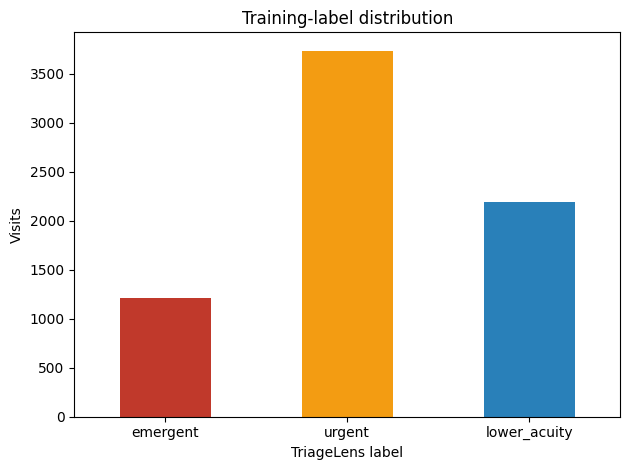

In [3]:
label_order = ['emergent', 'urgent', 'lower_acuity']
label_counts = train['triage_label'].value_counts().reindex(label_order)
label_percent = (label_counts / len(train) * 100).round(2)
display(pd.DataFrame({'rows': label_counts, 'percent': label_percent}))

ax = label_counts.plot.bar(
    color=['#c0392b', '#f39c12', '#2980b9'],
    title='Training-label distribution',
    ylabel='Visits',
)
ax.set_xlabel('TriageLens label')
ax.tick_params(axis='x', rotation=0)
plt.tight_layout()
plt.show()

## Training-feature missingness

Optional RFV positions and pain contain substantial missingness. Missingness indicators are already included, but imputation values must be learned from training data only during Day 5.

,missing_percent
RFV5,84.13
RFV4,72.13
RFV3,54.94
RFV2,30.94
PAINSCALE,28.93
BPDIAS,7.98
BPSYS,7.84
EPISODE,7.53
SEEN72,6.02
TEMPF,2.95


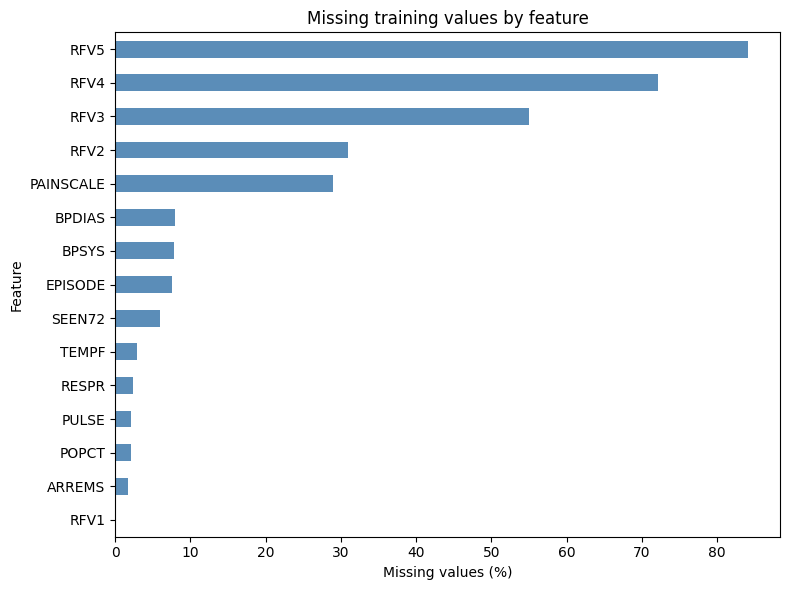

In [4]:
predictors = summary['predictor_columns']
missingness = (train[predictors].isna().mean() * 100).sort_values(ascending=False)
display(missingness.rename('missing_percent').round(2).to_frame())

ax = missingness[missingness > 0].sort_values().plot.barh(
    figsize=(8, 6),
    color='#5b8db8',
    title='Missing training values by feature',
    xlabel='Missing values (%)',
)
ax.set_ylabel('Feature')
plt.tight_layout()
plt.show()

## Numeric range review

These checks flag values outside broad review ranges; they do not diagnose bad data. Extreme emergency-department measurements can be real, so no values are removed or clipped here.

,min,max,outside_review_range
AGE,0.0,94.0,NaN
TEMPF,91.8,104.9,0.0
PULSE,6.0,217.0,6.0
RESPR,1.0,150.0,11.0
BPSYS,43.0,289.0,0.0
BPDIAS,25.0,190.0,0.0
POPCT,0.0,100.0,23.0
PAINSCALE,0.0,10.0,NaN


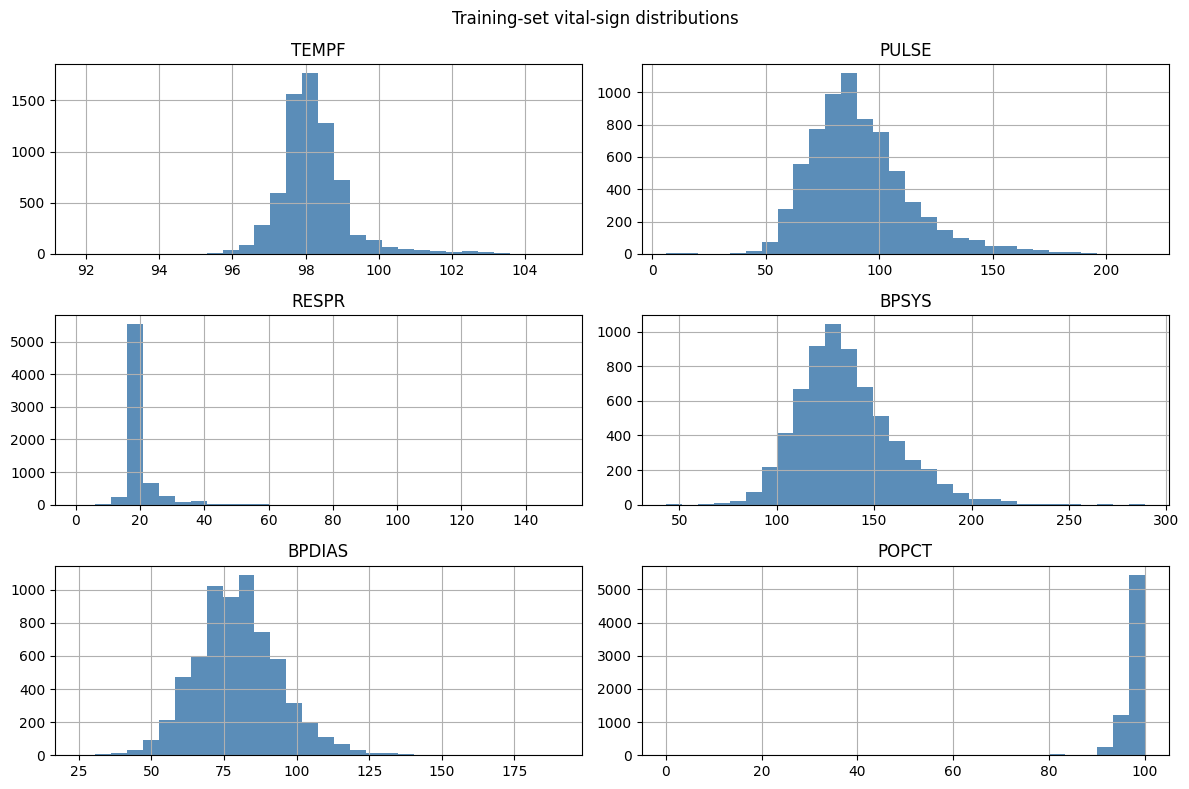

In [5]:
training_eda = summary['training_eda']
range_review = pd.DataFrame(training_eda['numeric_ranges']).T
range_review['outside_review_range'] = pd.Series(
    training_eda['values_outside_review_ranges']
)
display(range_review)

vital_columns = ['TEMPF', 'PULSE', 'RESPR', 'BPSYS', 'BPDIAS', 'POPCT']
train[vital_columns].hist(figsize=(12, 8), bins=30, color='#5b8db8')
plt.suptitle('Training-set vital-sign distributions')
plt.tight_layout()
plt.show()

## Reason-for-visit review

RFV codes are category identifiers, not numeric quantities. Day 5 should encode them categorically and safely ignore previously unseen validation or test categories.

,observed_codes,missing_percent
RFV1,424,0.07
RFV2,454,30.94
RFV3,401,54.94
RFV4,351,72.13
RFV5,266,84.13


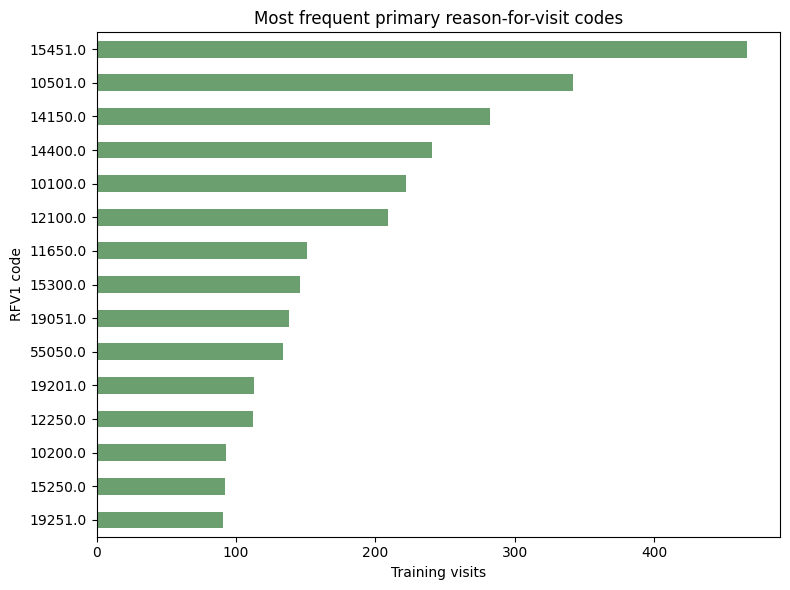

In [6]:
rfv_columns = [f'RFV{position}' for position in range(1, 6)]
rfv_review = pd.DataFrame({
    'observed_codes': train[rfv_columns].nunique(),
    'missing_percent': (train[rfv_columns].isna().mean() * 100).round(2),
})
display(rfv_review)

top_rfv1 = train['RFV1'].value_counts().head(15).sort_values()
ax = top_rfv1.plot.barh(
    figsize=(8, 6),
    color='#6c9f70',
    title='Most frequent primary reason-for-visit codes',
    xlabel='Training visits',
)
ax.set_ylabel('RFV1 code')
plt.tight_layout()
plt.show()

## Review conclusions

- The split sizes and class distributions match the Day 4 report.
- Model-ready files exclude direct target leakage, identifiers, and survey metadata.
- Duplicate predictor groups do not cross split boundaries.
- Missingness is substantial for optional RFV fields and pain.
- RFV fields require categorical treatment.
- Extreme vital-sign values remain flagged for error analysis rather than being silently removed.
- The test set remains reserved for final evaluation after model selection.